# DS605 Lab 7 - Image Representation, PCA and Eigenfaces
**Dataset:** AT&T (ORL) Database of Faces - 40 subjects x 10 images, 92x112 grayscale.



In [1]:
import os, glob, re
import numpy as np
import matplotlib.pyplot as plt
import cv2

SEED = 42
rng = np.random.default_rng(SEED)

DATA_DIR = "C:\\Users\\Yatri\\Desktop\\ml_lab07\\archive (2)"          # change if your folder has a different name
IMG_H, IMG_W = 112, 92          # ORL image size (height, width)
N_TRAIN_PER_SUBJECT = 8         # 8 train / 2 test images per subject
os.makedirs("figures", exist_ok=True)

## Part A - Image Representation

### A1. Read images as grayscale pixel matrices

In [2]:
def load_orl(data_dir):
    num = lambda s: int(re.findall(r"\d+", s)[0])
    subject_dirs = sorted(glob.glob(os.path.join(data_dir, "s*")),
                          key=lambda p: num(os.path.basename(p)))
    if not subject_dirs:
        raise FileNotFoundError(f"No subject folders (s1, s2, ...) found in '{data_dir}'")
    images, labels = [], []
    for d in subject_dirs:
        sid = num(os.path.basename(d))
        files = sorted(glob.glob(os.path.join(d, "*.pgm")),
                       key=lambda p: num(os.path.basename(p)))
        for f in files:
            img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)      # grayscale uint8 matrix (H x W)
            if img is None:
                raise IOError(f"Could not read {f}")
            images.append(img)
            labels.append(sid)
    return np.stack(images), np.array(labels)

images, y = load_orl(DATA_DIR)
print("Image tensor shape :", images.shape, "(n_images, height, width)")
print("Single image shape :", images[0].shape)
print("dtype              :", images.dtype)
print("Intensity range    :", images.min(), "to", images.max())
print("Subjects           :", len(np.unique(y)), "| images per subject:", np.unique(np.bincount(y)[1:]))
print("\nTop-left 5x5 pixel block of image 0:\n", images[0][:5, :5])

Image tensor shape : (400, 112, 92) (n_images, height, width)
Single image shape : (112, 92)
dtype              : uint8
Intensity range    : 0 to 251
Subjects           : 40 | images per subject: [10]

Top-left 5x5 pixel block of image 0:
 [[48 49 45 47 49]
 [45 52 39 46 56]
 [45 50 42 51 51]
 [49 46 47 47 50]
 [46 46 47 48 48]]


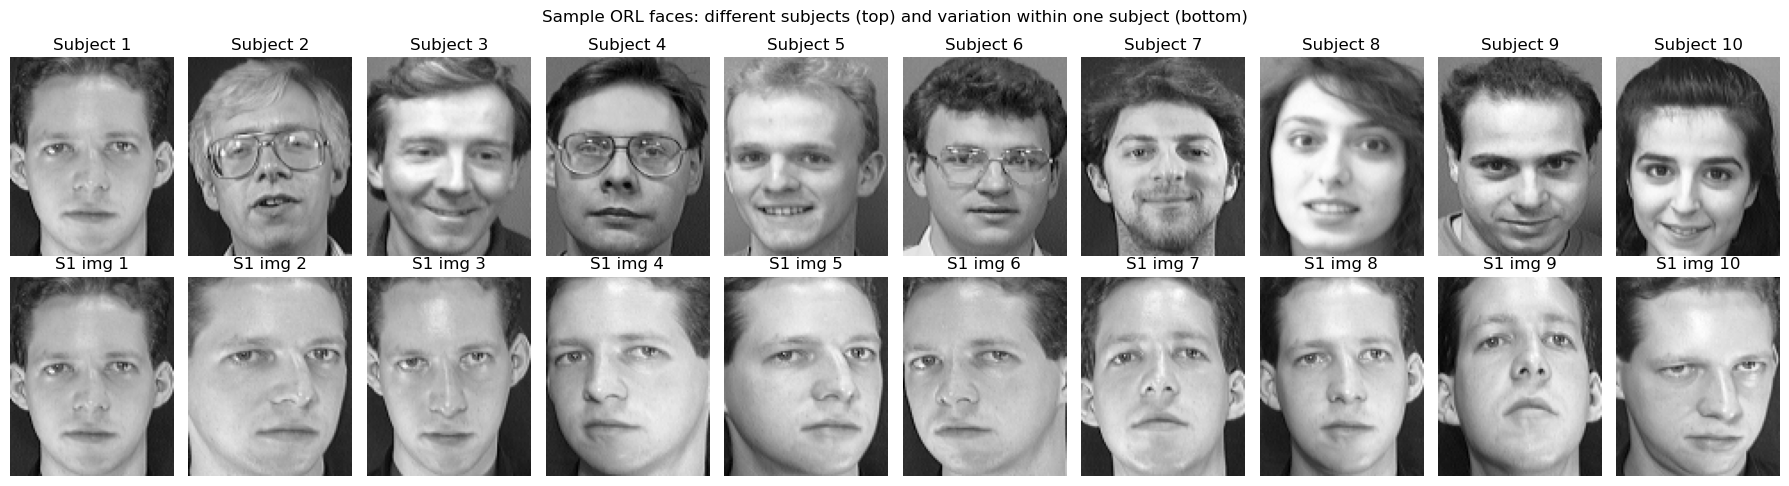

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(18, 5))
for i in range(10):                                   # first image of 10 different subjects
    axes[0, i].imshow(images[i * 10], cmap="gray"); axes[0, i].set_title(f"Subject {y[i*10]}"); axes[0, i].axis("off")
for i in range(10):                                   # all 10 images of subject 1
    axes[1, i].imshow(images[i], cmap="gray"); axes[1, i].set_title(f"S1 img {i+1}"); axes[1, i].axis("off")
plt.suptitle("Sample ORL faces: different subjects (top) and variation within one subject (bottom)")
plt.tight_layout(); plt.savefig("figures/sample_faces.png", dpi=120); plt.show()

### A2. Flatten each image into a feature vector and build the image matrix

In [4]:
n_images = images.shape[0]
X = images.reshape(n_images, -1).astype(np.float64) / 255.0   # scale to [0, 1]
print("Image matrix X :", X.shape, "-> each row is one face, each column one pixel")
print("Feature length :", IMG_H, "x", IMG_W, "=", IMG_H * IMG_W)
print("Labels y       :", y.shape, "| classes:", y.min(), "to", y.max())

# sanity check: flatten + reshape round-trips
assert np.array_equal(X[0].reshape(IMG_H, IMG_W), images[0] / 255.0)

Image matrix X : (400, 10304) -> each row is one face, each column one pixel
Feature length : 112 x 92 = 10304
Labels y       : (400,) | classes: 1 to 40


### A3. Reproducible stratified train-test split

In [5]:
train_idx, test_idx = [], []
for s in np.unique(y):
    idx = rng.permutation(np.where(y == s)[0])          # shuffled indices for subject s
    train_idx += idx[:N_TRAIN_PER_SUBJECT].tolist()
    test_idx  += idx[N_TRAIN_PER_SUBJECT:].tolist()
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

assert set(y_train) == set(y_test) == set(np.unique(y)), "every subject must be in both sets"
assert len(set(train_idx) & set(test_idx)) == 0
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train images per subject:", np.unique(np.bincount(y_train)[1:]),
      "| Test images per subject:", np.unique(np.bincount(y_test)[1:]))

Train: (320, 10304) | Test: (80, 10304)
Train images per subject: [8] | Test images per subject: [2]


## Part B - PCA, Eigenfaces and Compression

### B1. Mean face and centering

Centered data: (320, 10304) | column means ~ 0: True


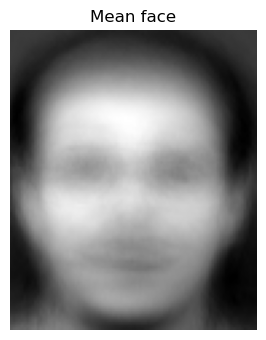

In [6]:
mean_face = X_train.mean(axis=0)            # mean computed from TRAINING data only
Xc = X_train - mean_face                    # centered training matrix (n_train x D)
n_train, D = Xc.shape
print("Centered data:", Xc.shape, "| column means ~ 0:", np.allclose(Xc.mean(axis=0), 0))

plt.figure(figsize=(3, 3.5)); plt.imshow(mean_face.reshape(IMG_H, IMG_W), cmap="gray")
plt.title("Mean face"); plt.axis("off"); plt.tight_layout(); plt.savefig("figures/mean_face.png", dpi=120); plt.show()

### B2. Principal directions - two approaches
**Approach 1: covariance / eigendecomposition.** The full covariance matrix is D x D = 10304 x 10304 (~850 MB), which is wasteful
when we only have 320 images. We use the standard Turk-Pentland trick: eigendecompose the small
n x n matrix `Xc Xc^T / (n-1)`. If `v` is its eigenvector, then `Xc^T v` is an eigenvector of the big covariance matrix
`Xc^T Xc / (n-1)` with the same eigenvalue.

**Approach 2: SVD.** `Xc = U S V^T`; rows of `V^T` are the principal directions and eigenvalues are `S^2 / (n-1)`.

In [7]:
# ---- Approach 1: eigendecomposition (small-matrix trick) ----
G = (Xc @ Xc.T) / (n_train - 1)                       # n x n
evals_g, evecs_g = np.linalg.eigh(G)                  # ascending order
order = np.argsort(evals_g)[::-1]
evals_cov, evecs_g = evals_g[order], evecs_g[:, order]

keep = evals_cov > 1e-10                              # drop the zero eigenvalue (centering costs 1 rank)
evals_cov, evecs_g = evals_cov[keep], evecs_g[:, keep]
W_cov = Xc.T @ evecs_g                                # map to pixel space (D x r)
W_cov /= np.linalg.norm(W_cov, axis=0)                # unit-length eigenfaces
r = len(evals_cov)
print("Eigendecomposition: non-zero components =", r)

# ---- Approach 2: SVD ----
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
evals_svd = (S ** 2) / (n_train - 1)
W_svd = Vt.T[:, :r]                                   # D x r
print("SVD               : singular values =", len(S), "| using first", r)

Eigendecomposition: non-zero components = 319
SVD               : singular values = 320 | using first 319


In [8]:
# ---- Compare the two approaches ----
print("Eigenvalues match      :", np.allclose(evals_cov, evals_svd[:r]))
cos = np.abs(np.sum(W_cov * W_svd, axis=0))           # |cosine| per component (sign is arbitrary)
print("Top-50 directions match (|cos| > 0.999):", np.all(cos[:50] > 0.999), "| min |cos| =", cos[:50].min().round(6))
print("Total variance (trace) :", evals_cov.sum().round(6), "vs", (np.sum(Xc**2) / (n_train - 1)).round(6))

Eigenvalues match      : True
Top-50 directions match (|cos| > 0.999): True | min |cos| = 1.0
Total variance (trace) : 245.297844 vs 245.297844


### B3. Explained variance and choosing the number of components

Minimum components for >= 90% variance: k = 99  (cumulative variance = 0.9001)
  80% variance -> 42 components
  90% variance -> 99 components
  95% variance -> 164 components
  99% variance -> 267 components


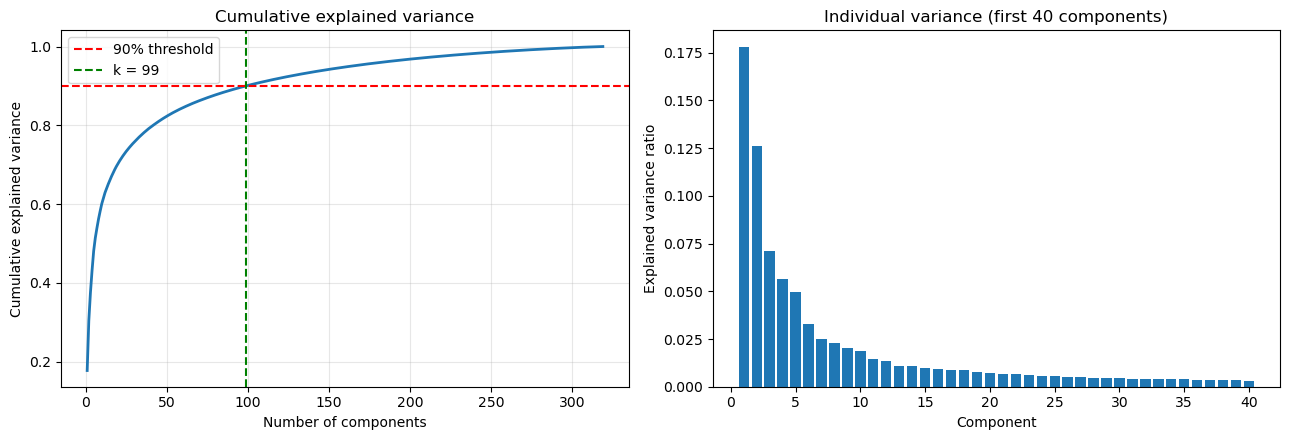

In [9]:
W = W_svd                                             # use the SVD basis from here on
explained_ratio = evals_svd[:r] / evals_svd[:r].sum()
cum_var = np.cumsum(explained_ratio)
k90 = int(np.searchsorted(cum_var, 0.90) + 1)
print(f"Minimum components for >= 90% variance: k = {k90}  (cumulative variance = {cum_var[k90-1]:.4f})")
for p in (0.80, 0.90, 0.95, 0.99):
    print(f"  {int(p*100)}% variance -> {int(np.searchsorted(cum_var, p) + 1)} components")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(np.arange(1, r + 1), cum_var, lw=2)
ax[0].axhline(0.90, color="r", ls="--", label="90% threshold")
ax[0].axvline(k90, color="g", ls="--", label=f"k = {k90}")
ax[0].set(xlabel="Number of components", ylabel="Cumulative explained variance", title="Cumulative explained variance")
ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar(np.arange(1, 41), explained_ratio[:40])
ax[1].set(xlabel="Component", ylabel="Explained variance ratio", title="Individual variance (first 40 components)")
plt.tight_layout(); plt.savefig("figures/explained_variance.png", dpi=120); plt.show()

### B4. Eigenfaces

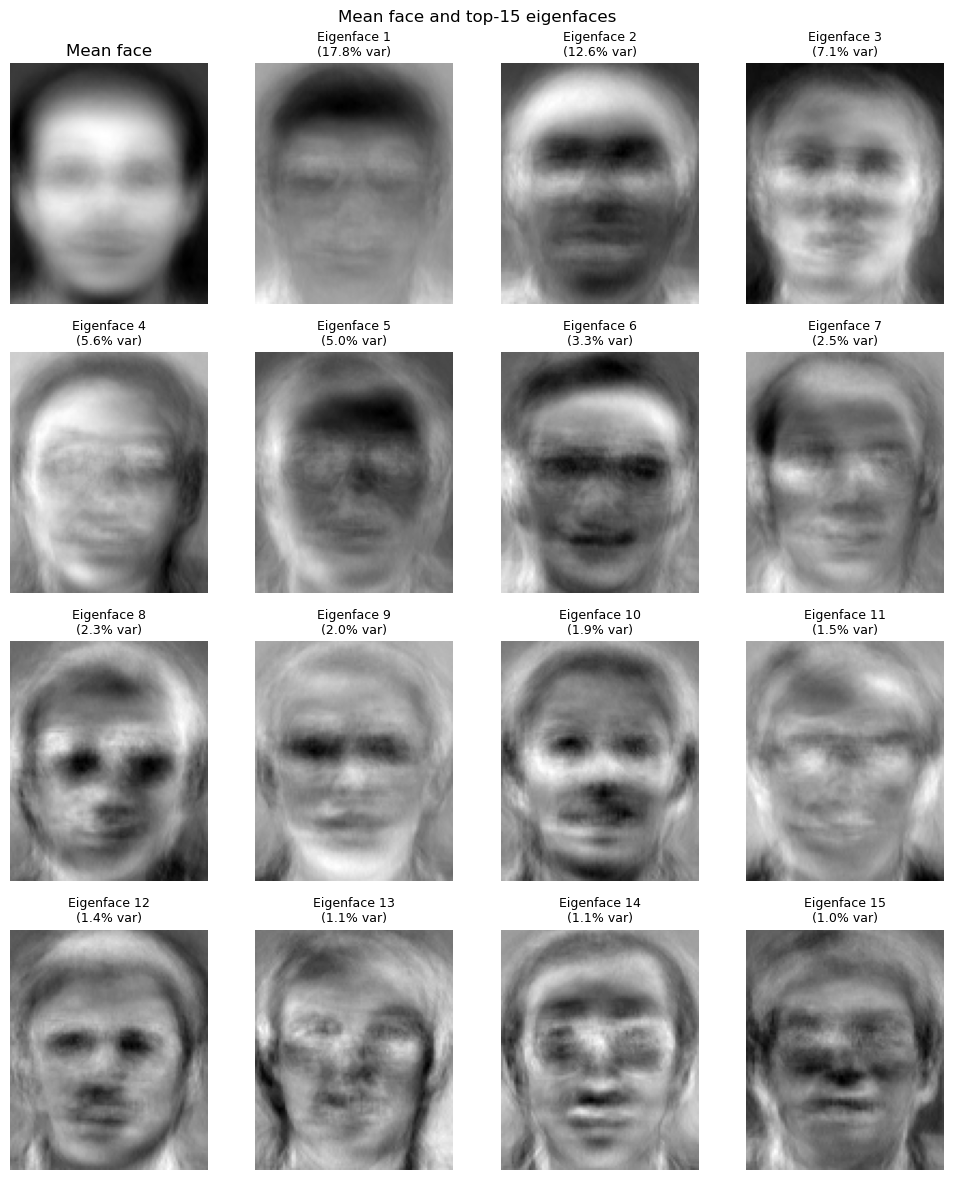

In [10]:
n_show = 15
fig, axes = plt.subplots(4, 4, figsize=(10, 12))
axes = axes.ravel()
axes[0].imshow(mean_face.reshape(IMG_H, IMG_W), cmap="gray"); axes[0].set_title("Mean face"); axes[0].axis("off")
for i in range(n_show):
    axes[i + 1].imshow(W[:, i].reshape(IMG_H, IMG_W), cmap="gray")
    axes[i + 1].set_title(f"Eigenface {i+1}\n({explained_ratio[i]*100:.1f}% var)", fontsize=9)
    axes[i + 1].axis("off")
plt.suptitle("Mean face and top-15 eigenfaces"); plt.tight_layout()
plt.savefig("figures/eigenfaces.png", dpi=120); plt.show()

### B5. Project into PCA space and store the reduced representation

In [12]:
Wk = W[:, :k90]                                       # D x k projection matrix
Z_train = Xc @ Wk                                     # n_train x k
Z_test  = (X_test - mean_face) @ Wk                   # test images use the TRAIN mean and basis
print("Z_train:", Z_train.shape, "| Z_test:", Z_test.shape)

np.savez_compressed("pca_representation.npz",
                    Z_train=Z_train, Z_test=Z_test, y_train=y_train, y_test=y_test,
                    components=Wk, mean_face=mean_face, k=k90)
print("Saved -> pca_representation.npz")

Z_train: (320, 99) | Z_test: (80, 99)
Saved -> pca_representation.npz


### B6. Reconstruction and quality comparison

In [13]:
def reconstruct(Z, Wk, mean):
    return Z @ Wk.T + mean

def mse(a, b):  return np.mean((a - b) ** 2, axis=1)
def psnr(a, b): return 10 * np.log10(1.0 / mse(a, b))          # pixel range is [0, 1]

ks = sorted(set([5, 10, 20, 50, k90, 100, 200, r]))
ks = [k for k in ks if k <= r]
rows = []
for k in ks:
    Zt = (X_test - mean_face) @ W[:, :k]
    Xr = reconstruct(Zt, W[:, :k], mean_face)
    rows.append((k, cum_var[k-1], mse(X_test, Xr).mean(), psnr(X_test, Xr).mean()))
print(f"{'k':>5} {'cum var':>9} {'test MSE':>11} {'test PSNR (dB)':>15}")
for k, cv, m, p in rows:
    print(f"{k:>5} {cv:>9.4f} {m:>11.6f} {p:>15.2f}")

    k   cum var    test MSE  test PSNR (dB)
    5    0.4812    0.012955           19.03
   10    0.6010    0.010254           20.02
   20    0.7030    0.008135           21.05
   50    0.8230    0.006033           22.38
   99    0.9001    0.004970           23.27
  100    0.9012    0.004956           23.28
  200    0.9680    0.004206           24.04
  319    1.0000    0.003802           24.52


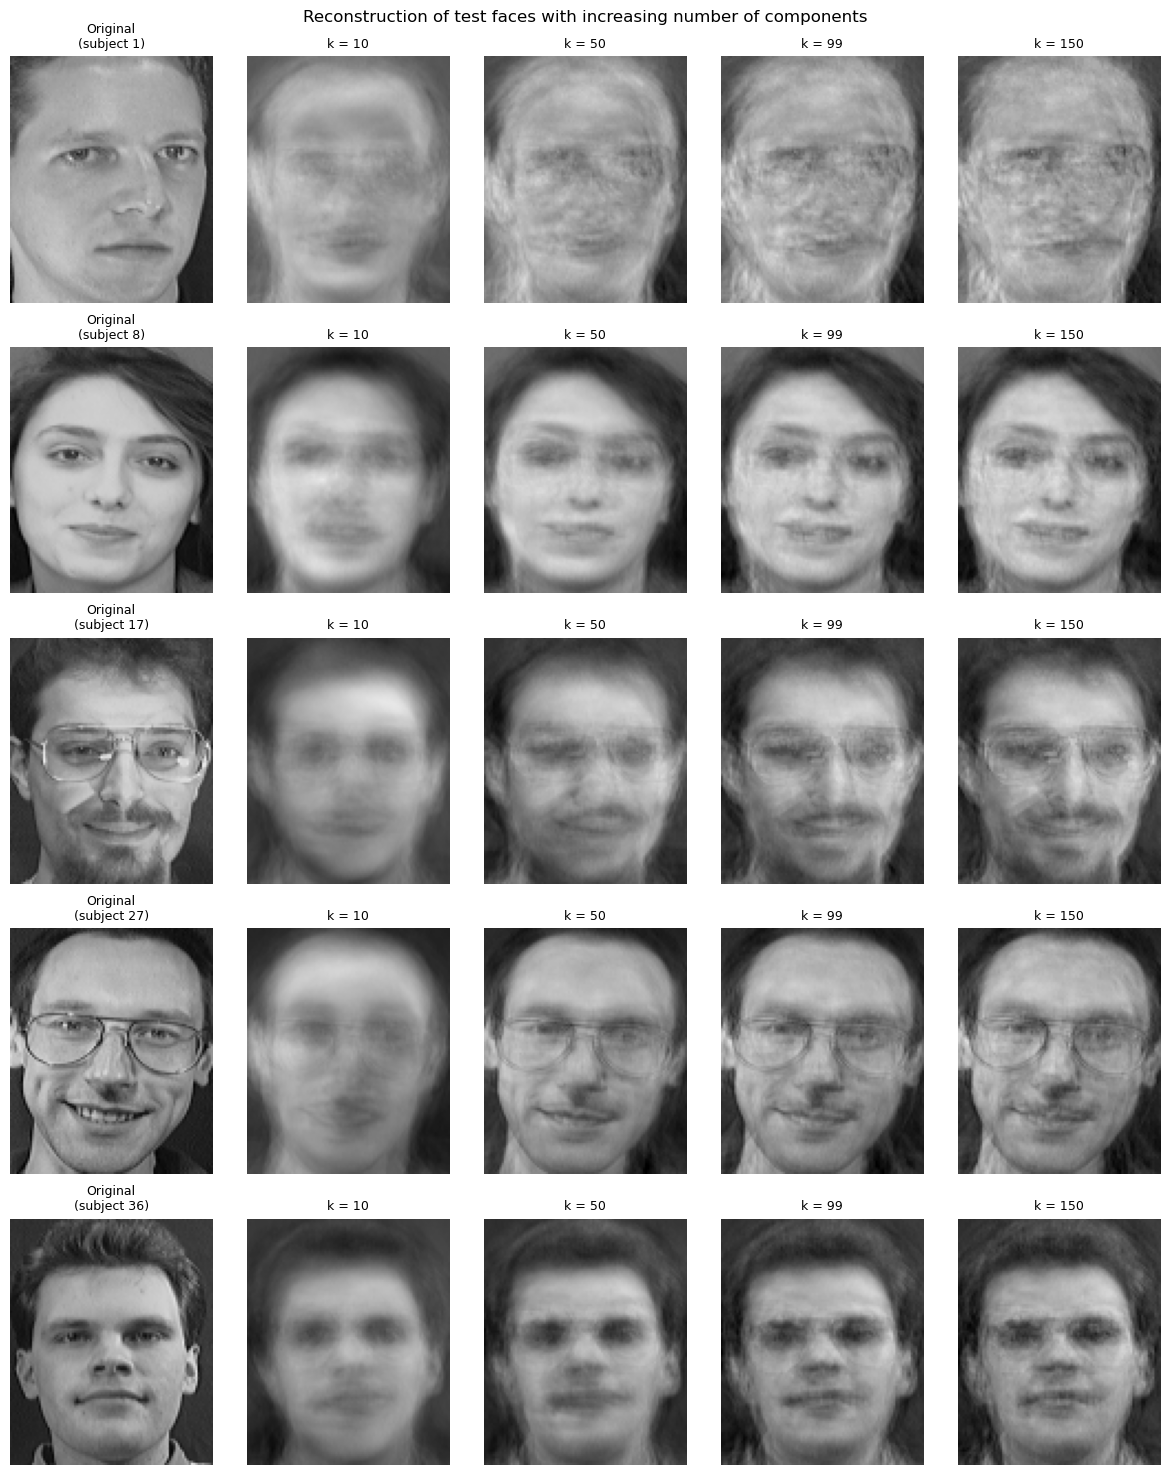

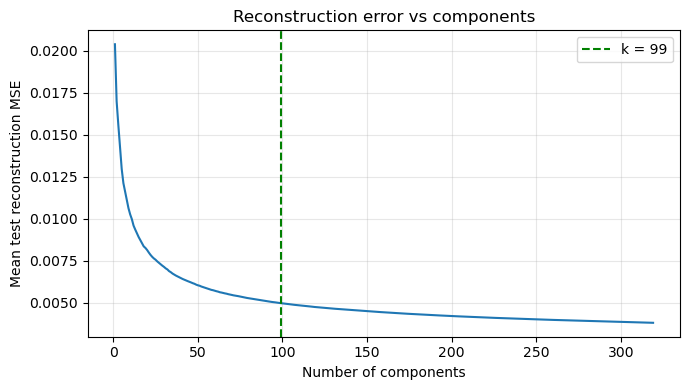

In [14]:
show_ks = [k for k in sorted(set([10, 50, k90, 150])) if k <= r]
sample_ids = [0, 15, 33, 52, 71]                      # a few test faces
fig, axes = plt.subplots(len(sample_ids), len(show_ks) + 1, figsize=(2.4 * (len(show_ks) + 1), 3 * len(sample_ids)))
for row, i in enumerate(sample_ids):
    axes[row, 0].imshow(X_test[i].reshape(IMG_H, IMG_W), cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Original\n(subject {y_test[i]})", fontsize=9); axes[row, 0].axis("off")
    for col, k in enumerate(show_ks, start=1):
        z = (X_test[i] - mean_face) @ W[:, :k]
        rec = (z @ W[:, :k].T + mean_face).reshape(IMG_H, IMG_W)
        axes[row, col].imshow(np.clip(rec, 0, 1), cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"k = {k}", fontsize=9); axes[row, col].axis("off")
plt.suptitle("Reconstruction of test faces with increasing number of components")
plt.tight_layout(); plt.savefig("figures/reconstruction_examples.png", dpi=120); plt.show()

ks_curve = np.arange(1, r + 1)
curve = [mse(X_test, reconstruct((X_test - mean_face) @ W[:, :k], W[:, :k], mean_face)).mean() for k in ks_curve]
plt.figure(figsize=(7, 4)); plt.plot(ks_curve, curve); plt.axvline(k90, color="g", ls="--", label=f"k = {k90}")
plt.xlabel("Number of components"); plt.ylabel("Mean test reconstruction MSE"); plt.title("Reconstruction error vs components")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.savefig("figures/reconstruction_error_curve.png", dpi=120); plt.show()

### B7. Storage: original pixels vs PCA representation

In [15]:
bytes_f = X_train.itemsize                            # 8 bytes for float64
orig_train = n_train * D * bytes_f
pca_train  = n_train * k90 * bytes_f                  # reduced coordinates
pca_model  = (D * k90 + D) * bytes_f                  # projection matrix + mean face (stored once)
per_img_orig, per_img_pca = D * bytes_f, k90 * bytes_f

print(f"Per image  : original = {per_img_orig/1024:.1f} KB | PCA = {per_img_pca/1024:.2f} KB "
      f"-> {D / k90:.1f}x smaller (D / k = {D}/{k90})")
print(f"Train set  : original = {orig_train/1e6:.2f} MB | PCA codes = {pca_train/1e6:.3f} MB")
print(f"PCA model (basis + mean, stored once) = {pca_model/1e6:.2f} MB")
print(f"Total PCA (codes + model) = {(pca_train+pca_model)/1e6:.2f} MB "
      f"vs {orig_train/1e6:.2f} MB -> {orig_train/(pca_train+pca_model):.2f}x")
print("\nNote: the model cost is fixed, so the saving grows as more faces are stored with the same basis.")

Per image  : original = 80.5 KB | PCA = 0.77 KB -> 104.1x smaller (D / k = 10304/99)
Train set  : original = 26.38 MB | PCA codes = 0.253 MB
PCA model (basis + mean, stored once) = 8.24 MB
Total PCA (codes + model) = 8.50 MB vs 26.38 MB -> 3.10x

Note: the model cost is fixed, so the saving grows as more faces are stored with the same basis.


## Part C - Recognition in PCA Space
For every test face we compute its PCA coordinates (train mean + train eigenfaces) and find the **closest stored training face**
(1-nearest-neighbour). Distances are computed with NumPy. We compare this with matching on the raw 10,304 pixels.

In [16]:
import time

# Full PCA coordinates (all r components); the first k columns = a k-component representation
Z_train_full = Xc @ W
Z_test_full  = (X_test - mean_face) @ W

def pairwise_euclid(A, B):
    a2 = (A ** 2).sum(1)[:, None]; b2 = (B ** 2).sum(1)[None, :]
    return np.sqrt(np.maximum(a2 + b2 - 2 * A @ B.T, 0.0))

def pairwise_cosine(A, B):
    An = A / np.linalg.norm(A, axis=1, keepdims=True)
    Bn = B / np.linalg.norm(B, axis=1, keepdims=True)
    return 1.0 - An @ Bn.T

def nn_match(D, y_train):
    nn = D.argmin(axis=1)                      # index of the closest training face
    return nn, y_train[nn]

# --- PCA space (k90 components), Euclidean ---
t0 = time.perf_counter()
D_pca = pairwise_euclid(Z_test, Z_train)
nn_pca, pred_pca = nn_match(D_pca, y_train)
t_pca = time.perf_counter() - t0
acc_pca = (pred_pca == y_test).mean()

# --- PCA space, cosine distance ---
D_cos = pairwise_cosine(Z_test, Z_train)
_, pred_cos = nn_match(D_cos, y_train)
acc_cos = (pred_cos == y_test).mean()

# --- raw pixels, Euclidean ---
t0 = time.perf_counter()
D_raw = pairwise_euclid(X_test, X_train)
nn_raw, pred_raw = nn_match(D_raw, y_train)
t_raw = time.perf_counter() - t0
acc_raw = (pred_raw == y_test).mean()

print(f"{'Representation':<28}{'dim':>7}{'accuracy':>10}{'match time (s)':>16}")
print(f"{'Raw pixels (Euclidean)':<28}{D:>7}{acc_raw:>10.4f}{t_raw:>16.4f}")
print(f"{'PCA k='+str(k90)+' (Euclidean)':<28}{k90:>7}{acc_pca:>10.4f}{t_pca:>16.4f}")
print(f"{'PCA k='+str(k90)+' (cosine)':<28}{k90:>7}{acc_cos:>10.4f}")
print(f"\nPCA matching uses {D / k90:.0f}x fewer features per face than raw pixels.")

Representation                  dim  accuracy  match time (s)
Raw pixels (Euclidean)        10304    0.9875          0.0360
PCA k=99 (Euclidean)             99    0.9875          0.0049
PCA k=99 (cosine)                99    1.0000

PCA matching uses 104x fewer features per face than raw pixels.


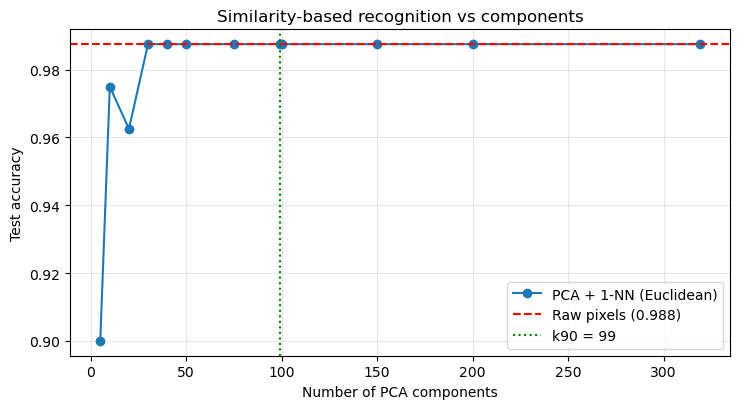

k =   5: accuracy = 0.9000
k =  10: accuracy = 0.9750
k =  20: accuracy = 0.9625
k =  30: accuracy = 0.9875
k =  40: accuracy = 0.9875
k =  50: accuracy = 0.9875
k =  75: accuracy = 0.9875
k =  99: accuracy = 0.9875
k = 100: accuracy = 0.9875
k = 150: accuracy = 0.9875
k = 200: accuracy = 0.9875
k = 319: accuracy = 0.9875


In [17]:
# Accuracy of the similarity matcher as the number of components changes
ks_sim = sorted(set([5, 10, 20, 30, 40, 50, 75, k90, 100, 150, 200, r]))
ks_sim = [k for k in ks_sim if k <= r]
acc_k = []
for k in ks_sim:
    _, p = nn_match(pairwise_euclid(Z_test_full[:, :k], Z_train_full[:, :k]), y_train)
    acc_k.append((p == y_test).mean())

plt.figure(figsize=(7.5, 4.2))
plt.plot(ks_sim, acc_k, "o-", label="PCA + 1-NN (Euclidean)")
plt.axhline(acc_raw, color="r", ls="--", label=f"Raw pixels ({acc_raw:.3f})")
plt.axvline(k90, color="g", ls=":", label=f"k90 = {k90}")
plt.xlabel("Number of PCA components"); plt.ylabel("Test accuracy"); plt.title("Similarity-based recognition vs components")
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig("figures/similarity_accuracy_vs_k.png", dpi=120); plt.show()
for k, a in zip(ks_sim, acc_k): print(f"k = {k:>3}: accuracy = {a:.4f}")

Correct: 79 | Incorrect: 1 (of 80)


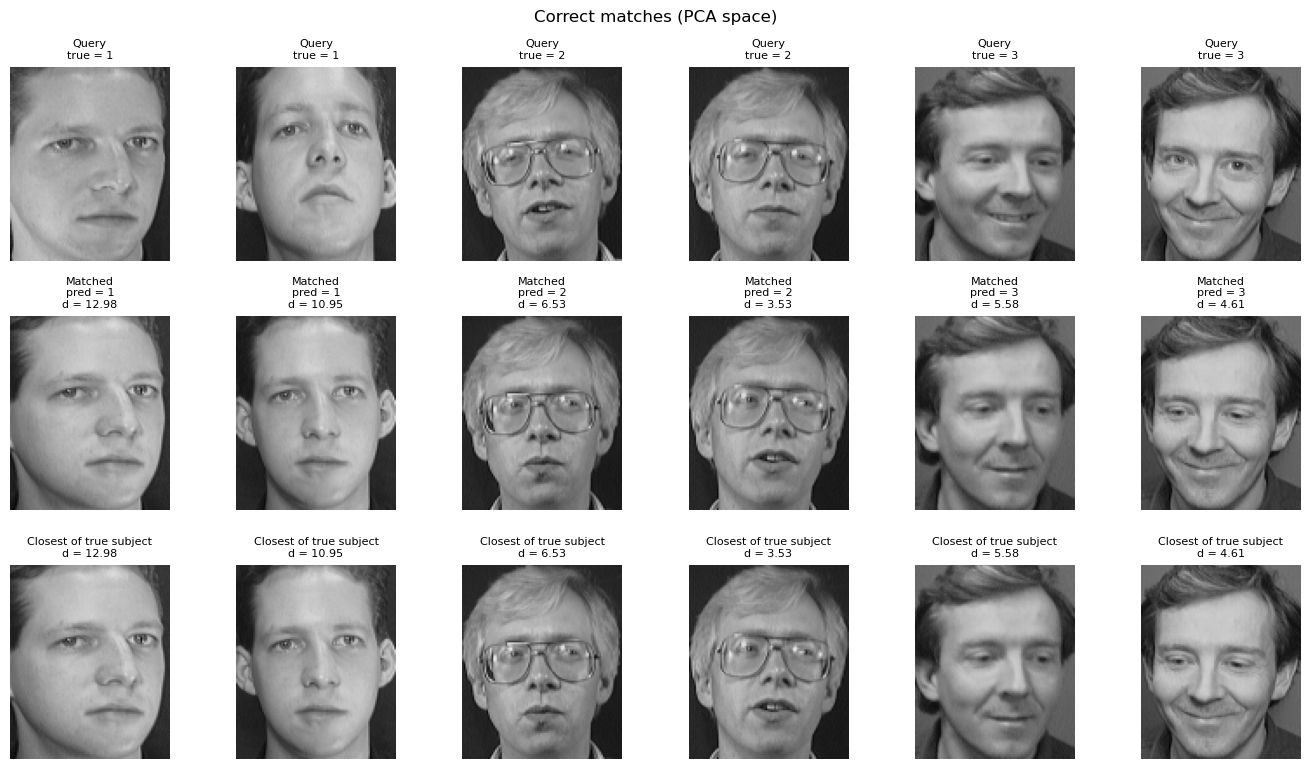

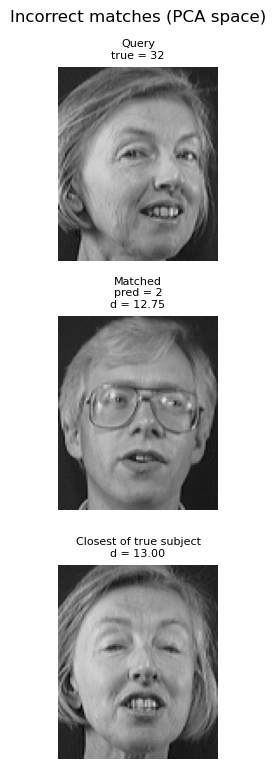


Misclassified test faces:
  test #63: true = 32, predicted = 2
Of these, raw pixels classify 0 correctly.


In [18]:
def show_matches(ids, title, fname, n=6):
    ids = ids[:n]
    if len(ids) == 0:
        print(f"No examples for: {title}"); return
    fig, axes = plt.subplots(3, len(ids), figsize=(2.3 * len(ids), 7.8), squeeze=False)
    for c, i in enumerate(ids):
        same = np.where(y_train == y_test[i])[0]
        j_true = same[np.argmin(D_pca[i, same])]            # closest training face of the TRUE subject
        panels = [(X_test[i], f"Query\ntrue = {y_test[i]}"),
                  (X_train[nn_pca[i]], f"Matched\npred = {pred_pca[i]}\nd = {D_pca[i, nn_pca[i]]:.2f}"),
                  (X_train[j_true], f"Closest of true subject\nd = {D_pca[i, j_true]:.2f}")]
        for r_, (img, t) in enumerate(panels):
            axes[r_, c].imshow(img.reshape(IMG_H, IMG_W), cmap="gray", vmin=0, vmax=1)
            axes[r_, c].set_title(t, fontsize=8); axes[r_, c].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=120); plt.show()

correct_ids = np.where(pred_pca == y_test)[0]
wrong_ids   = np.where(pred_pca != y_test)[0]
print(f"Correct: {len(correct_ids)} | Incorrect: {len(wrong_ids)} (of {len(y_test)})")
show_matches(correct_ids, "Correct matches (PCA space)", "figures/matches_correct.png")
show_matches(wrong_ids,   "Incorrect matches (PCA space)", "figures/matches_incorrect.png")

if len(wrong_ids):
    print("\nMisclassified test faces:")
    for i in wrong_ids:
        print(f"  test #{i}: true = {y_test[i]}, predicted = {pred_pca[i]}")
    rescued = np.sum((pred_raw[wrong_ids] == y_test[wrong_ids]))
    print(f"Of these, raw pixels classify {rescued} correctly.")

## Part D - Traditional Machine Learning on PCA Features
Scikit-learn is used **only here**, as allowed by the assignment. Classifiers are trained on the PCA coordinates.
Model selection (number of components, scaling, hyper-parameters) is done with **stratified cross-validation on the training set only**,
so the 80 test faces are used once, for the final report.

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
import pandas as pd
import warnings; warnings.filterwarnings("ignore")

class TopK(BaseEstimator, TransformerMixin):
    # keep only the first k PCA components (so k can be tuned inside a pipeline)
    def __init__(self, k=50): self.k = k
    def fit(self, X, y=None): return self
    def transform(self, X): return X[:, :self.k]

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)   # 8 train images/subject -> 2 per fold

### D1. Default models on the k90 PCA features vs the similarity baseline

In [20]:
default_models = {
    "KNN (k=1)":            KNeighborsClassifier(n_neighbors=1),
    "KNN (k=3)":            KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression":  LogisticRegression(max_iter=5000),
    "SVM (linear)":         SVC(kernel="linear"),
    "SVM (RBF)":            SVC(kernel="rbf"),
}
rows = [("Similarity 1-NN, raw pixels", D, acc_raw, np.nan),
        ("Similarity 1-NN, PCA (NumPy)", k90, acc_pca, np.nan)]
for name, model in default_models.items():
    t0 = time.perf_counter()
    model.fit(Z_train, y_train)
    acc = (model.predict(Z_test) == y_test).mean()
    rows.append((name, k90, acc, time.perf_counter() - t0))
df_default = pd.DataFrame(rows, columns=["Model", "Features", "Test accuracy", "Fit+predict (s)"])
df_default.round(4)

,Model,Features,Test accuracy,Fit+predict (s)
0,"Similarity 1-NN, raw pixels",10304,0.9875,NaN
1,"Similarity 1-NN, PCA (NumPy)",99,0.9875,NaN
2,KNN (k=1),99,0.9875,0.1011
3,KNN (k=3),99,0.9625,0.0044
4,Logistic Regression,99,0.9875,0.0608
5,SVM (linear),99,0.9875,0.0123
6,SVM (RBF),99,0.9875,0.0147


### D2. Effect of the number of retained components (4-fold CV on the training set)

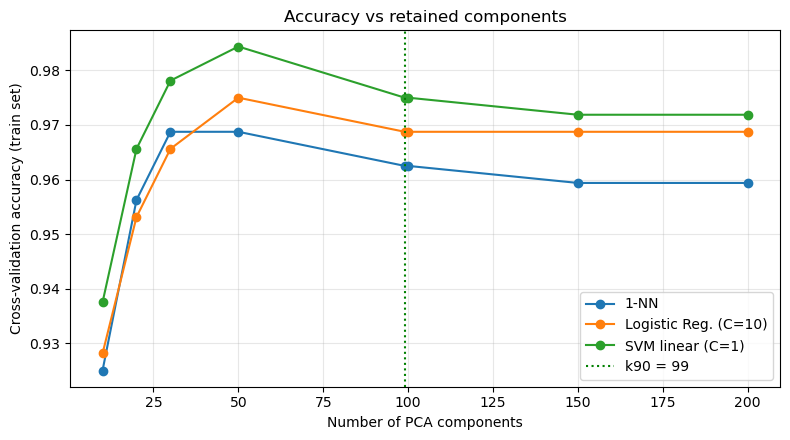

       1-NN  Logistic Reg. (C=10)  SVM linear (C=1)
k                                                  
10   0.9250                0.9281            0.9375
20   0.9562                0.9531            0.9656
30   0.9688                0.9656            0.9781
50   0.9688                0.9750            0.9844
99   0.9625                0.9688            0.9750
100  0.9625                0.9688            0.9750
150  0.9594                0.9688            0.9719
200  0.9594                0.9688            0.9719


In [21]:
sweep_models = {
    "1-NN":              KNeighborsClassifier(n_neighbors=1),
    "Logistic Reg. (C=10)": LogisticRegression(C=10, max_iter=5000),
    "SVM linear (C=1)":  SVC(kernel="linear", C=1),
}
ks_d = sorted(set([10, 20, 30, 50, k90, 100, 150, 200]))
ks_d = [k for k in ks_d if k <= r]
sweep = {name: [] for name in sweep_models}
for k in ks_d:
    for name, model in sweep_models.items():
        sweep[name].append(cross_val_score(model, Z_train_full[:, :k], y_train, cv=cv).mean())

plt.figure(figsize=(8, 4.5))
for name, scores in sweep.items():
    plt.plot(ks_d, scores, "o-", label=name)
plt.axvline(k90, color="g", ls=":", label=f"k90 = {k90}")
plt.xlabel("Number of PCA components"); plt.ylabel("Cross-validation accuracy (train set)")
plt.title("Accuracy vs retained components"); plt.grid(alpha=.3); plt.legend()
plt.tight_layout(); plt.savefig("figures/ml_accuracy_vs_k.png", dpi=120); plt.show()
print(pd.DataFrame(sweep, index=pd.Index(ks_d, name="k")).round(4))

### D3. Hyper-parameter tuning (components, scaling and model settings) with GridSearchCV

In [22]:
k_grid = sorted(set([10, 20, 30, 50, k90, 100, 150]))
k_grid = [k for k in k_grid if k <= r]
scalers = [StandardScaler(), "passthrough"]

searches = {
    "KNN": (KNeighborsClassifier(),
            {"topk__k": k_grid, "scale": scalers,
             "clf__n_neighbors": [1, 3, 5], "clf__weights": ["uniform", "distance"]}),
    "Logistic Regression": (LogisticRegression(max_iter=5000),
            {"topk__k": k_grid, "scale": scalers, "clf__C": [0.1, 1, 10, 100]}),
    "SVM": (SVC(),
            {"topk__k": k_grid, "scale": scalers,
             "clf__kernel": ["linear", "rbf"], "clf__C": [1, 10, 100]}),
}

tuned, rows = {}, []
for name, (clf, grid) in searches.items():
    pipe = Pipeline([("topk", TopK()), ("scale", "passthrough"), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=cv, n_jobs=-1, refit=True)
    t0 = time.perf_counter(); gs.fit(Z_train_full, y_train); fit_t = time.perf_counter() - t0
    test_acc = (gs.predict(Z_test_full) == y_test).mean()
    tuned[name] = gs
    bp = {k_.split("__")[-1]: (type(v).__name__ if not isinstance(v, (int, float, str)) else v) for k_, v in gs.best_params_.items()}
    rows.append((name, gs.best_params_["topk__k"], gs.best_score_, test_acc, fit_t, bp))
    print(f"{name}: best CV = {gs.best_score_:.4f} | test = {test_acc:.4f} | params = {bp}")

KNN: best CV = 0.9688 | test = 0.9875 | params = {'n_neighbors': 1, 'weights': 'uniform', 'scale': 'passthrough', 'k': 30}
Logistic Regression: best CV = 0.9781 | test = 1.0000 | params = {'C': 0.1, 'scale': 'passthrough', 'k': 50}
SVM: best CV = 0.9844 | test = 0.9875 | params = {'C': 1, 'kernel': 'linear', 'scale': 'passthrough', 'k': 50}


### D4. Final comparison table

                            Model  Features used  CV accuracy (train)  Test accuracy  Compression vs raw
      Similarity 1-NN, raw pixels          10304                  NaN         0.9875                 1.0
Similarity 1-NN, PCA k=99 (NumPy)             99                  NaN         0.9875               104.1
                      KNN (tuned)             30               0.9688         0.9875               343.5
      Logistic Regression (tuned)             50               0.9781         1.0000               206.1
                      SVM (tuned)             50               0.9844         0.9875               206.1


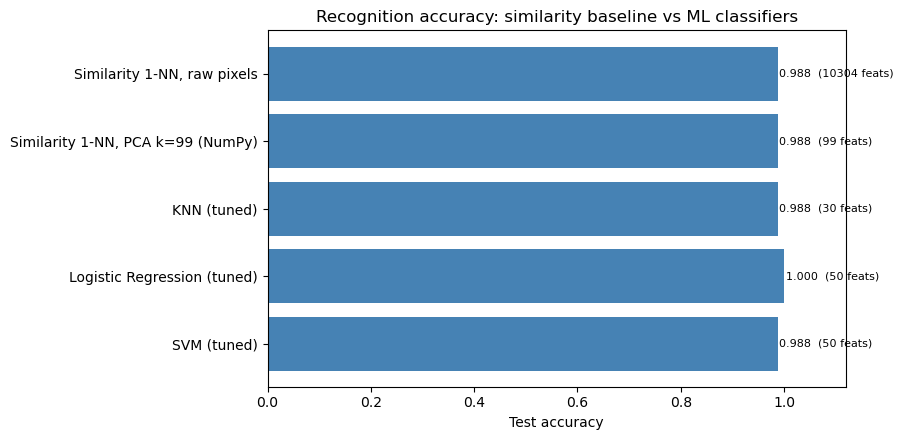


Best model by cross-validation: SVM -> test accuracy 0.9875
Misclassified test faces: [(63, 32, 2)] (index, true, predicted)


In [23]:
final = [("Similarity 1-NN, raw pixels", D, np.nan, acc_raw),
         ("Similarity 1-NN, PCA k=%d (NumPy)" % k90, k90, np.nan, acc_pca)]
for name, kk, cvs, ta, ft, bp in rows:
    final.append((f"{name} (tuned)", kk, cvs, ta))
df_final = pd.DataFrame(final, columns=["Model", "Features used", "CV accuracy (train)", "Test accuracy"])
df_final["Compression vs raw"] = (D / df_final["Features used"]).round(1)
df_final.to_csv("results_comparison.csv", index=False)
print(df_final.round(4).to_string(index=False))

plt.figure(figsize=(9, 4.5))
plt.barh(df_final["Model"], df_final["Test accuracy"], color="steelblue")
for i, (a, f) in enumerate(zip(df_final["Test accuracy"], df_final["Features used"])):
    plt.text(a + 0.003, i, f"{a:.3f}  ({int(f)} feats)", va="center", fontsize=8)
plt.xlim(0, 1.12); plt.xlabel("Test accuracy"); plt.title("Recognition accuracy: similarity baseline vs ML classifiers")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.savefig("figures/model_comparison.png", dpi=120); plt.show()

best_name = max(tuned, key=lambda n: (tuned[n].best_score_))
best_model = tuned[best_name]
pred_best = best_model.predict(Z_test_full)
print(f"\nBest model by cross-validation: {best_name} -> test accuracy {(pred_best == y_test).mean():.4f}")
print("Misclassified test faces:", [(int(i), int(y_test[i]), int(pred_best[i])) for i in np.where(pred_best != y_test)[0]], "(index, true, predicted)")

## Observations (replace with your own numbers after running)
- **Raw vs PCA matching:** PCA matching uses about D/k90 times fewer features per face and should give accuracy close to (often equal to or better than) raw pixels, because the discarded directions are mostly noise.
- **Distance measure:** compare Euclidean and cosine distance in PCA space.
- **Number of components:** accuracy rises quickly for small k and then plateaus; beyond the plateau extra components add storage and compute but no accuracy.
- **Classifiers vs similarity baseline:** compare KNN, logistic regression and SVM against the 1-NN baseline; note that standardising PCA scores can help or hurt (it boosts low-variance, noisy components).
- **Tuning:** model selection used cross-validation on the training set only; the test set was used once for the final numbers.
- **Errors:** look at the incorrect matches - they are typically faces with strong expression, pose or glasses changes.
- **Caveat:** with only 2 test images per subject (80 total), one error changes accuracy by 1.25 points, so small differences between models are not significant.